In [2]:
import numpy as np
print("🧬Welcome to GroupDNA!")
print("Your whatsApp group is about to be decoded...")

🧬Welcome to GroupDNA!
Your whatsApp group is about to be decoded...


In [4]:
with open('/content/hostel_bois.txt', 'r',
encoding='utf-8') as f:
   content=f.read()
print(content[:1000])

01/04/24, 01:12 - Messages and calls are end-to-end encrypted. No one outside of this chat, not even WhatsApp, can read or listen to them. Tap to learn more.
01/04/24, 01:13 - Priya created group "Hostel Bois 4ever"
01/04/24, 01:14 - Priya added you
01/04/24, 01:17 - Rahul: scene fix
01/04/24, 01:17 - Rahul: haan
01/04/24, 01:18 - Rahul: kya scene
01/04/24, 02:13 - Rahul: abhi free hai?
01/04/24, 02:13 - Rahul: abey
01/04/24, 02:14 - Rahul: bhai sun na
01/04/24, 07:46 - Priya: I have extra notes if anyone wants
01/04/24, 09:20 - Priya: Anyone needs help with anything?
01/04/24, 10:42 - Priya: Don't forget to call home guys
01/04/24, 11:37 - Rahul: ja yaar
01/04/24, 11:38 - Rahul: kya scene hai bhai
01/04/24, 11:38 - Rahul: bhai chai pite hai
01/04/24, 11:44 - Priya: Did you eat anything today?
01/04/24, 11:52 - Priya: Everyone doing okay with studies?
01/04/24, 12:39 - Karan: Today's class was honestly the most interesting one we have had this semester, the professor went off topic com

In [6]:
import re

messages = re.findall(
    r'(\d{2}/\d{2}/\d{2}), (\d{1,2}:\d{2}) - (.*?): (.*)',
    content
)

print("Total parsed messages:", len(messages))
print("First 5 messages:\n")

for msg in messages[:5]:
    print(msg)

Total parsed messages: 3174
First 5 messages:

('01/04/24', '01:17', 'Rahul', 'scene fix')
('01/04/24', '01:17', 'Rahul', 'haan')
('01/04/24', '01:18', 'Rahul', 'kya scene')
('01/04/24', '02:13', 'Rahul', 'abhi free hai?')
('01/04/24', '02:13', 'Rahul', 'abey')


In [8]:
print("Total parsed messages:", len(messages))
print("Total lines in file:", len(content.splitlines()))
print("Unparsed lines:", len(content.splitlines()) - len(messages))

Total parsed messages: 3174
Total lines in file: 3178
Unparsed lines: 4


In [9]:
from collections import Counter

senders = [msg[2] for msg in messages]
sender_counts = Counter(senders)

print("Total messages:", len(messages))
print("Total members:", len(sender_counts))
print("\nMessages per member:")

for name, count in sender_counts.most_common():
    print(name, ":", count)


Total messages: 3174
Total members: 6

Messages per member:
Rahul : 953
Priya : 718
Neha : 635
Aman : 490
Karan : 354
Vikas : 24


In [10]:
from datetime import datetime
from collections import Counter

days = []

for msg in messages:
    date = datetime.strptime(msg[0], "%d/%m/%y")
    days.append(date.strftime("%A"))

day_counts = Counter(days)

for day, count in day_counts.most_common():
    print(day, ":", count, "messages")

Wednesday : 483 messages
Monday : 482 messages
Thursday : 475 messages
Saturday : 459 messages
Sunday : 446 messages
Tuesday : 426 messages
Friday : 403 messages


In [11]:
hour_counts = Counter()

for msg in messages:
    time = msg[1]
    hour = int(time.split(':')[0])
    hour_counts[hour] += 1

for hour, count in hour_counts.most_common():
    print(f"{hour}:00 - {count} messages")

18:00 - 248 messages
19:00 - 228 messages
12:00 - 193 messages
16:00 - 189 messages
21:00 - 177 messages
17:00 - 173 messages
20:00 - 166 messages
14:00 - 162 messages
10:00 - 160 messages
13:00 - 159 messages
23:00 - 159 messages
9:00 - 151 messages
15:00 - 131 messages
8:00 - 122 messages
22:00 - 116 messages
11:00 - 114 messages
4:00 - 110 messages
2:00 - 83 messages
1:00 - 82 messages
3:00 - 77 messages
0:00 - 57 messages
7:00 - 55 messages
6:00 - 33 messages
5:00 - 29 messages


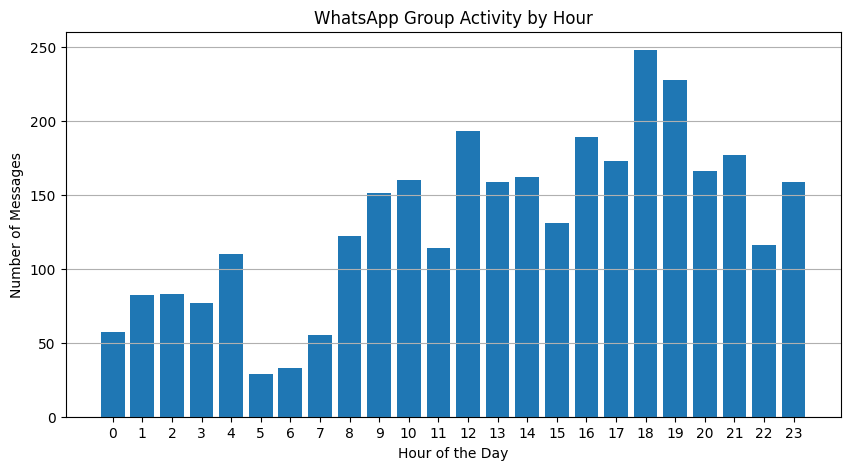

In [12]:
import matplotlib.pyplot as plt

hours = sorted(hour_counts.keys())
counts = [hour_counts[h] for h in hours]

plt.figure(figsize=(10,5))
plt.bar(hours, counts)
plt.xlabel("Hour of the Day")
plt.ylabel("Number of Messages")
plt.title("WhatsApp Group Activity by Hour")
plt.xticks(range(24))
plt.grid(axis='y')
plt.show()

In [13]:
from collections import Counter
import re

all_text = " ".join(msg[3] for msg in messages)

words = re.findall(r'\b[a-zA-Z]{3,}\b', all_text.lower())

common_words = Counter(words)

print("Top 20 most used words:")
for word, count in common_words.most_common(20):
    print(word, ":", count)

Top 20 most used words:
the : 1494
and : 1013
was : 400
you : 328
this : 326
how : 321
guys : 318
today : 292
about : 274
for : 270
hai : 268
his : 217
that : 211
have : 209
just : 208
everyone : 203
which : 202
telling : 179
from : 174
bhai : 160


In [14]:
stop_words = {
    'the', 'and', 'you', 'are', 'for', 'this', 'that', 'was', 'with',
    'have', 'but', 'not', 'what', 'all', 'your', 'can', 'they', 'just',
    'its', 'from', 'will', 'like', 'about', 'who', 'out', 'get', 'when',
    'how', 'why', 'his', 'her', 'she', 'him', 'our', 'had', 'has',
    'been', 'were', 'there', 'then', 'one', 'too', 'very'
}

clean_words = [word for word in words if word not in stop_words]

clean_counts = Counter(clean_words)

print("Top 20 meaningful words:")
for word, count in clean_counts.most_common(20):
    print(word, ":", count)

Top 20 meaningful words:
guys : 318
today : 292
hai : 268
everyone : 203
which : 202
telling : 179
bhai : 160
anyone : 157
started : 150
scene : 145
entire : 145
please : 141
yaar : 139
kya : 133
now : 121
everything : 121
came : 116
sleep : 112
raha : 101
three : 97


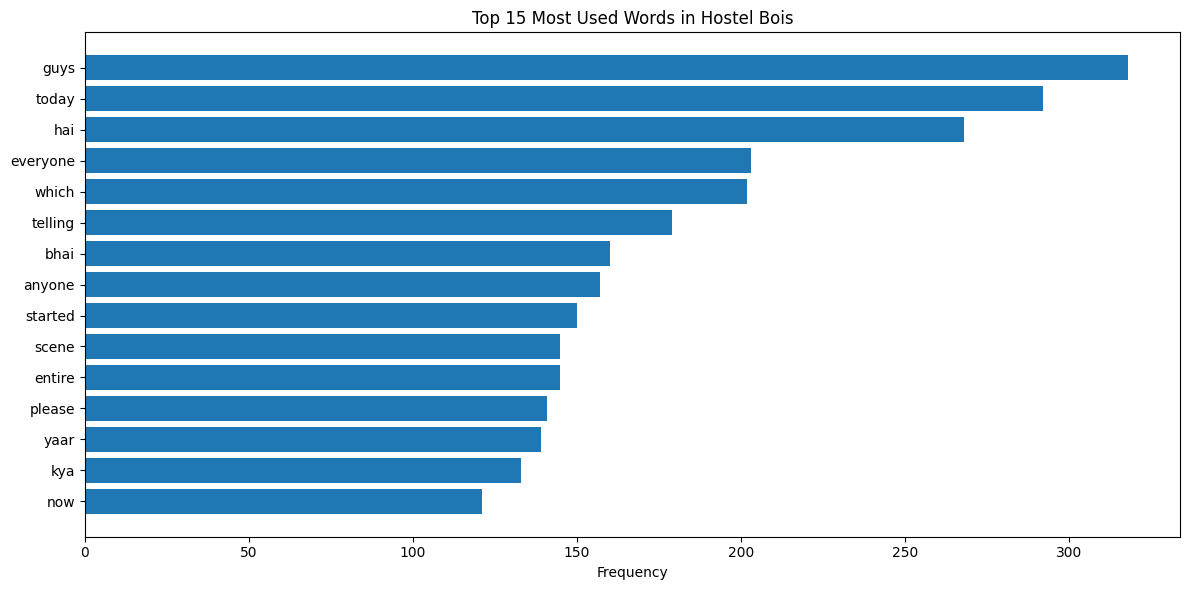

In [15]:
top_words = clean_counts.most_common(15)

word_labels = [item[0] for item in top_words]
word_values = [item[1] for item in top_words]

plt.figure(figsize=(12, 6))
plt.barh(word_labels[::-1], word_values[::-1])
plt.xlabel("Frequency")
plt.title("Top 15 Most Used Words in Hostel Bois")
plt.tight_layout()
plt.show()

In [16]:
from datetime import datetime
from collections import defaultdict

# Convert messages into datetime objects
chat_data = []

for msg in messages:
    dt = datetime.strptime(msg[0] + " " + msg[1], "%d/%m/%y %H:%M")
    chat_data.append((dt, msg[2], msg[3]))

chat_data.sort(key=lambda x: x[0])

# Response times
response_times = defaultdict(list)

for i in range(1, len(chat_data)):
    previous = chat_data[i-1]
    current = chat_data[i]

    if previous[1] != current[1]:
        gap = (current[0] - previous[0]).total_seconds() / 60
        if gap <= 60:  # consider replies within 1 hour
            response_times[current[1]].append(gap)

# Longest gap between each member's messages
member_times = defaultdict(list)

for dt, sender, text in chat_data:
    member_times[sender].append(dt)

silent_streaks = {}

for member, times in member_times.items():
    times.sort()
    gaps = [(times[i] - times[i-1]).total_seconds() / 3600
            for i in range(1, len(times))]
    silent_streaks[member] = max(gaps, default=0)

print("AVERAGE RESPONSE TIME (minutes)")
for member, times in sorted(response_times.items(),
                            key=lambda x: sum(x[1])/len(x[1])):
    print(f"{member}: {sum(times)/len(times):.2f} min")

print("\nLONGEST SILENT STREAK (hours between messages)")
for member, hours in sorted(silent_streaks.items(),
                           key=lambda x: x[1], reverse=True):
    print(f"{member}: {hours:.2f} hours")

AVERAGE RESPONSE TIME (minutes)
Rahul: 19.26 min
Neha: 19.32 min
Priya: 20.20 min
Karan: 21.68 min
Aman: 23.21 min
Vikas: 24.65 min

LONGEST SILENT STREAK (hours between messages)
Vikas: 292.63 hours
Neha: 28.37 hours
Rahul: 24.67 hours
Aman: 21.85 hours
Karan: 20.70 hours
Priya: 15.78 hours


In [17]:
# 🧬 Personality Archetypes

member_hours = defaultdict(list)
member_texts = defaultdict(list)

for dt, sender, text in chat_data:
    member_hours[sender].append(dt.hour)
    member_texts[sender].append(text)

total_messages = len(messages)

print("🧬 GROUP PERSONALITY REPORT\n")

for member, count in sender_counts.most_common():

    hours = member_hours[member]
    avg_length = sum(len(t) for t in member_texts[member]) / len(member_texts[member])

    night_messages = sum(1 for h in hours if h >= 22 or h <= 5)
    morning_messages = sum(1 for h in hours if 5 <= h <= 9)

    night_ratio = night_messages / count
    morning_ratio = morning_messages / count

    if count < total_messages * 0.05:
        archetype = "👻 Silent Observer"

    elif night_ratio > 0.4:
        archetype = "🌙 Night Owl"

    elif morning_ratio > 0.4:
        archetype = "🌅 Early Bird"

    elif avg_length > 100:
        archetype = "📖 Storyteller"

    elif count > total_messages * 0.20:
        archetype = "📢 Group Spammer"

    else:
        archetype = "😎 Balanced Member"

    print(f"{member} → {archetype}")

🧬 GROUP PERSONALITY REPORT

Rahul → 📢 Group Spammer
Priya → 📢 Group Spammer
Neha → 📢 Group Spammer
Aman → 🌙 Night Owl
Karan → 📖 Storyteller
Vikas → 👻 Silent Observer


In [18]:
# 🧬 GroupDNA Activity Matrix using NumPy

member_names = list(sender_counts.keys())

activity_matrix = np.zeros((len(member_names), 24), dtype=int)

member_index = {name: i for i, name in enumerate(member_names)}

for msg in messages:
    member = msg[2]
    hour = int(msg[1].split(':')[0])

    activity_matrix[member_index[member], hour] += 1

print("Activity Matrix Shape:", activity_matrix.shape)
print("\nRows = Members | Columns = Hours (0–23)\n")

print(activity_matrix)

Activity Matrix Shape: (6, 24)

Rows = Members | Columns = Hours (0–23)

[[  3  15  17  17  22  10  17  17  24  17  25  15  58  48  45  53  73  49
  105  76  41  92  60  54]
 [  0   0   0   0   0   0  13  20  47  65  62  61  57  48  44  29  32  40
   38  60  43  32  18   9]
 [  0   0   0   0   0   0   0   4  12  16  20  16  37  25  32  27  27  27
   25  32  23  14   9   8]
 [  0   0   0   0   0  19   3  13  36  52  52  22  39  36  27  10  37  47
   62  50  45  27  28  30]
 [ 54  67  66  60  88   0   0   0   0   0   0   0   0   0  14  11  19   7
   16   8  13  11   0  56]
 [  0   0   0   0   0   0   0   1   3   1   1   0   2   2   0   1   1   3
    2   2   1   1   1   2]]


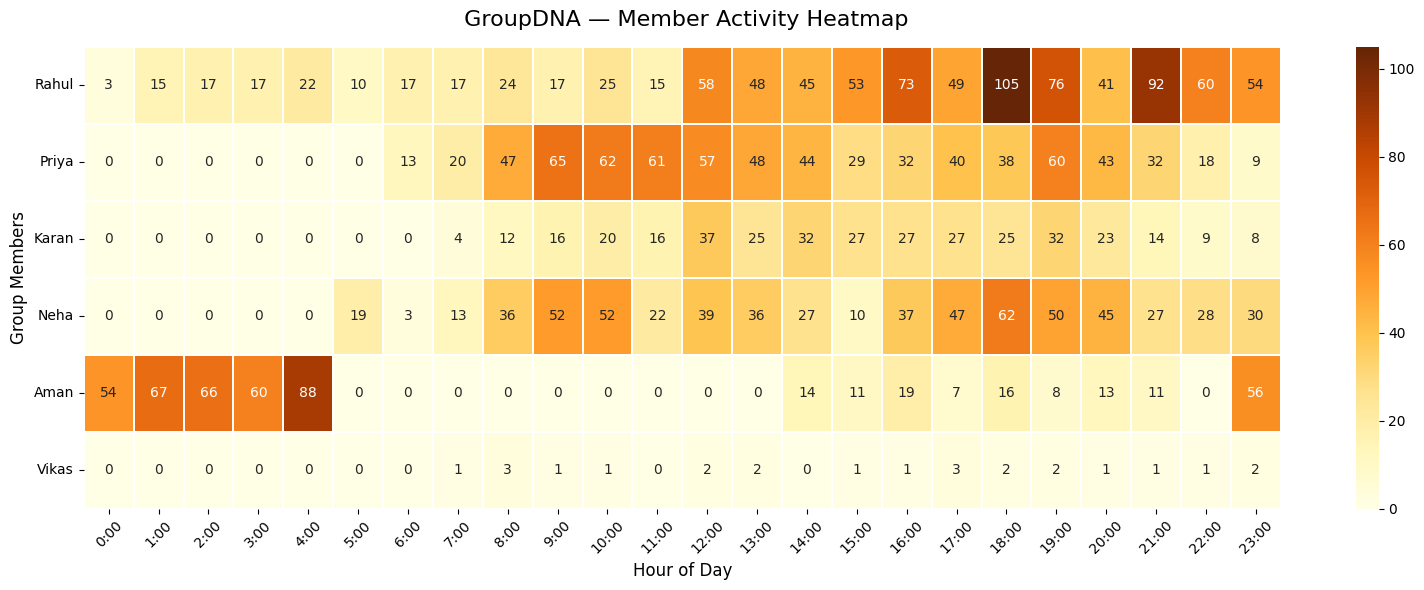

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(16, 6))

sns.heatmap(
    activity_matrix,
    xticklabels=[f"{h}:00" for h in range(24)],
    yticklabels=member_names,
    cmap="YlOrBr",
    annot=True,
    fmt="d",
    linewidths=0.3,
    linecolor="white"
)

plt.title(" GroupDNA — Member Activity Heatmap", fontsize=16, pad=15)
plt.xlabel("Hour of Day", fontsize=12)
plt.ylabel("Group Members", fontsize=12)
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [21]:
# 🧬 GroupDNA Final Report

from datetime import datetime

dates = [datetime.strptime(msg[0], "%d/%m/%y") for msg in messages]

print("=" * 50)
print("       🧬 GROUPDNA — CHAT ANALYSIS REPORT")
print("=" * 50)

print("\n📊 GROUP OVERVIEW")
print("Total Messages:", len(messages))
print("Total Members:", len(sender_counts))
print("Chat Started:", min(dates).strftime("%d %B %Y"))
print("Chat Ended:", max(dates).strftime("%d %B %Y"))

print("\n🏆 MOST ACTIVE MEMBER")
print(sender_counts.most_common(1)[0])

print("\n📅 MOST ACTIVE DAY")
print(day_counts.most_common(1)[0])

print("\n⏰ PEAK CHAT HOUR")
print(hour_counts.most_common(1)[0])

print("\n💬 TOP 10 WORDS")
for word, count in clean_counts.most_common(10):
    print(word, ":", count)

print("\n⚡ RESPONSE ANALYSIS")
if response_times:
    fastest = min(response_times.items(),
                  key=lambda x: sum(x[1])/len(x[1]))
    print("Fastest average responder:", fastest[0])
    print("Average response:", round(sum(fastest[1])/len(fastest[1]), 2), "minutes")

print("\n👻 LONGEST SILENT STREAK")
if silent_streaks:
    ghost = max(silent_streaks.items(), key=lambda x: x[1])
    print(ghost[0], ":", round(ghost[1], 2), "hours")

print("\n" + "=" * 50)
print("       END OF GROUPDNA REPORT")
print("=" * 50)

       🧬 GROUPDNA — CHAT ANALYSIS REPORT

📊 GROUP OVERVIEW
Total Messages: 3174
Total Members: 6
Chat Started: 01 April 2024
Chat Ended: 30 May 2024

🏆 MOST ACTIVE MEMBER
('Rahul', 953)

📅 MOST ACTIVE DAY
('Wednesday', 483)

⏰ PEAK CHAT HOUR
(18, 248)

💬 TOP 10 WORDS
guys : 318
today : 292
hai : 268
everyone : 203
which : 202
telling : 179
bhai : 160
anyone : 157
started : 150
scene : 145

⚡ RESPONSE ANALYSIS
Fastest average responder: Rahul
Average response: 19.26 minutes

👻 LONGEST SILENT STREAK
Vikas : 292.63 hours

       END OF GROUPDNA REPORT
